# Case study: Early economy of the Mirage league

The main analysis of historical leagues has been completed using a consistent analytical pipeline including data preparation, exploratory analysis, economic indicators, PCA, and clustering methods. However, during the course of the project, a new Path of Exile league, **Mirage**, was released on March 6. At the time of completing the analysis, only seven days of market data were available for this league.

Because the dataset for the Mirage league is still limited, it was not included in the main historical analysis to avoid methodological inconsistencies. Instead, it is analysed separately as a case study focusing on the early phase - **launch hype**- of league economies.

To ensure comparability, the same economic indicators used in the main analysis are calculated for the first six days of all leagues, including Mirage. This allows the early economic structure of the new league to be compared with the early-stage economies of previous leagues. The new league is then projected into the existing analytical framework using PCA and clustering methods, which makes it possible to determine whether its early market dynamics resemble any of the previously identified types of league economies.

This case study therefore serves as an exploratory extension of the project and demonstrates how the developed analytical framework can be applied to analyse the economic characteristics of newly released leagues.

### Importing libraries

In [61]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from adjustText import adjust_text
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

### Importing data

In [43]:
#importing already processed datasets for items and players
items= pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/items_processed_day.csv", sep=";", low_memory=False)
players = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/players_data_processed/players_processed_day.csv", sep=";", low_memory=False)

#imporing new datasets for items and players
items_mirage= pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_raw/Mirage.items.csv", sep=";", low_memory=False)
players_mirage= pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/players_data_raw/players_mirage.csv", sep=";", low_memory=False)

## Minimal cleaning of new datasets
Preparing the data only doing what is needed for the case study analysis

### Players new data

In [44]:
# add Day column
players_mirage["Date"] = pd.to_datetime(players_mirage["Date"])
league_start = players_mirage.groupby("League")["Date"].transform("min")
players_mirage["Day"] = (players_mirage["Date"]-league_start).dt.days + 1
players_mirage

,League,Date,Players,Day
0,Mirage,2026-03-06,190653.0,1
1,Mirage,2026-03-07,158206.0,2
2,Mirage,2026-03-08,156804.0,3
3,Mirage,2026-03-09,135034.0,4
4,Mirage,2026-03-10,127003.0,5
5,Mirage,2026-03-11,120098.0,6
6,Mirage,2026-03-12,113917.0,7


### Items new data

In [45]:
# making sure that League column is consistent across datasets
items_mirage["League"] = "Mirage"

In [46]:
#removing unnecessary columns
items_mirage = items_mirage.drop(columns=['Id','Variant','BaseType'])
items_mirage

,League,Date,Type,Name,Links,Value,Confidence
0,Mirage,2026-03-07,Oil,Prismatic Oil,NaN,90.81,Low
1,Mirage,2026-03-08,Oil,Prismatic Oil,NaN,16.00,Medium
2,Mirage,2026-03-09,Oil,Prismatic Oil,NaN,32.00,Medium
3,Mirage,2026-03-10,Oil,Prismatic Oil,NaN,47.00,Medium
4,Mirage,2026-03-11,Oil,Prismatic Oil,NaN,50.00,High
...,...,...,...,...,...,...,...
90896,Mirage,2026-03-08,BaseType,Linden Kite Shield,NaN,25.00,Low
90897,Mirage,2026-03-09,BaseType,Linden Kite Shield,NaN,25.00,Low
90898,Mirage,2026-03-10,BaseType,Linden Kite Shield,NaN,25.00,Low
90899,Mirage,2026-03-11,BaseType,Linden Kite Shield,NaN,25.00,Low


In [48]:
#add Day column
items_mirage["Date"] = pd.to_datetime(items_mirage["Date"])
league_start = items_mirage.groupby("League")["Date"].transform("min")
items_mirage["Day"] = (items_mirage["Date"]-league_start).dt.days + 1

In [49]:
# Filtering records with 5 and 6 links (keeping only base versions)
items_mirage = items_mirage[~items_mirage["Links"].isin(["5 links", "6 links"])]
items_mirage

,League,Date,Type,Name,Links,Value,Confidence,Day
59,Mirage,2026-03-06,Oil,Sepia Oil,NaN,1.00,High,1
66,Mirage,2026-03-06,Oil,Verdant Oil,NaN,1.00,Low,1
73,Mirage,2026-03-06,Oil,Clear Oil,NaN,1.00,High,1
86,Mirage,2026-03-06,Oil,Amber Oil,NaN,1.00,High,1
129,Mirage,2026-03-06,Incubator,Gemcutter's Incubator,NaN,2.00,Low,1
...,...,...,...,...,...,...,...,...
90882,Mirage,2026-03-12,BaseType,Military Staff,NaN,22.93,Low,7
90886,Mirage,2026-03-12,BaseType,Branded Kite Shield,NaN,40.93,Low,7
90889,Mirage,2026-03-12,BaseType,Nubuck Gloves,NaN,40.93,Low,7
90895,Mirage,2026-03-12,BaseType,Recurve Bow,NaN,40.93,Low,7


In [50]:
#drop links column
items_mirage = items_mirage.drop(columns=["Links"])

In [51]:
# handling missing values
items_mirage.isna().sum()

League        0
Date          0
Type          0
Name          0
Value         0
Confidence    0
Day           0
dtype: int64

## Merging old and new datasets

In [52]:
items_all = pd.concat([items, items_mirage])
players_all = pd.concat([players, players_mirage])

## League economic indicators - for 7 first days of each league

In [54]:
# filtering first 7 days of each league
items_all = items_all[items_all["Day"] <= 7]
players_all = players_all[players_all["Day"] <= 7]

### Item data aggregation

In [55]:
league_market = (items_all.groupby("League").agg(avg_price=("Value","mean"),median_price=("Value","median"),unique_items=("Name","nunique"),total_market_value=("Value","sum")).reset_index())
avg_daily_listings = (items_all.groupby(["League","Day"]).size().groupby("League").mean().reset_index(name="avg_daily_listings"))

league_market = league_market.merge(avg_daily_listings, on="League")
league_market

,League,avg_price,median_price,unique_items,total_market_value,avg_daily_listings
0,Affliction,47.227888,5.0,3949,6.661021e+06,20148.571429
1,Ancestor,49.245977,6.4,6134,7.933872e+06,23015.285714
2,Keepers,56.651735,4.0,4467,9.412459e+06,23735.142857
3,Mercenaries,58.251932,5.0,4239,9.378736e+06,23000.428571
4,Mirage,164.293524,3.0,2235,1.493231e+07,12984.000000
5,Necropolis,59.677240,5.0,4083,8.845301e+06,21174.142857
6,Settlers,63.822146,5.0,4177,1.046447e+07,23423.285714


### Players data aggregation

In [56]:
league_players = (players_all.groupby("League").agg(mean_daily_players=("Players","mean")).reset_index())
league_players

,League,mean_daily_players
0,Affliction,121784.428571
1,Ancestor,113243.571429
2,Keepers,132576.285714
3,Mercenaries,130558.571429
4,Mirage,143102.142857
5,Necropolis,119227.285714
6,Settlers,173436.285714


### Market Value Concentration

In [58]:
#top 1% item value share
def market_concentration(df):
    total_value = df["Value"].sum()
    top_n = int(len(df) * 0.01)
    top_value = df.nlargest(top_n, "Value")["Value"].sum()

    return pd.Series({"top_value_share": top_value / total_value})

market_concentration = items_all.groupby("League").apply(market_concentration, include_groups=False).reset_index()
market_concentration

,League,top_value_share
0,Affliction,0.578356
1,Ancestor,0.486585
2,Keepers,0.660915
3,Mercenaries,0.582176
4,Mirage,0.542215
5,Necropolis,0.608234
6,Settlers,0.688694


### Merging datasets

In [59]:
league_economy = (league_market.merge(market_concentration, on="League").merge(league_players, on="League"))
league_economy

,League,avg_price,median_price,unique_items,total_market_value,avg_daily_listings,top_value_share,mean_daily_players
0,Affliction,47.227888,5.0,3949,6.661021e+06,20148.571429,0.578356,121784.428571
1,Ancestor,49.245977,6.4,6134,7.933872e+06,23015.285714,0.486585,113243.571429
2,Keepers,56.651735,4.0,4467,9.412459e+06,23735.142857,0.660915,132576.285714
3,Mercenaries,58.251932,5.0,4239,9.378736e+06,23000.428571,0.582176,130558.571429
4,Mirage,164.293524,3.0,2235,1.493231e+07,12984.000000,0.542215,143102.142857
5,Necropolis,59.677240,5.0,4083,8.845301e+06,21174.142857,0.608234,119227.285714
6,Settlers,63.822146,5.0,4177,1.046447e+07,23423.285714,0.688694,173436.285714


### Market indicators per player

In [60]:
league_economy["listings_per_player"] = (league_economy["avg_daily_listings"] / league_economy["mean_daily_players"])
league_economy["market_value_per_player"] = (league_economy["total_market_value"] / league_economy["mean_daily_players"])

league_economy

,League,avg_price,median_price,unique_items,total_market_value,avg_daily_listings,top_value_share,mean_daily_players,listings_per_player,market_value_per_player
0,Affliction,47.227888,5.0,3949,6.661021e+06,20148.571429,0.578356,121784.428571,0.165445,54.695181
1,Ancestor,49.245977,6.4,6134,7.933872e+06,23015.285714,0.486585,113243.571429,0.203237,70.060239
2,Keepers,56.651735,4.0,4467,9.412459e+06,23735.142857,0.660915,132576.285714,0.179030,70.996552
3,Mercenaries,58.251932,5.0,4239,9.378736e+06,23000.428571,0.582176,130558.571429,0.176169,71.835466
4,Mirage,164.293524,3.0,2235,1.493231e+07,12984.000000,0.542215,143102.142857,0.090732,104.347213
5,Necropolis,59.677240,5.0,4083,8.845301e+06,21174.142857,0.608234,119227.285714,0.177595,74.188562
6,Settlers,63.822146,5.0,4177,1.046447e+07,23423.285714,0.688694,173436.285714,0.135054,60.336109


## PCA analysis

### 1. Filtering non-numerical data

In [74]:
pca_indicators=league_economy.drop(columns=["League"])

### 2. Data standarisation

In [75]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_indicators)

### 3. Applying PCA function

In [76]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

### 4. Explained variance of the principal components

Text(0, 0.5, 'Explained variance')

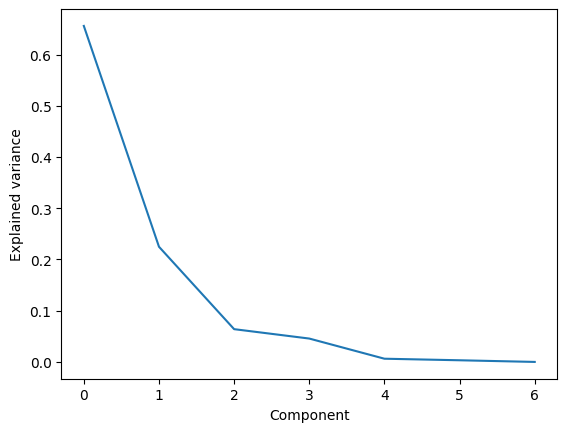

In [77]:
explained_variance = pca.explained_variance_ratio_

plt.plot(explained_variance)
plt.xlabel("Component")
plt.ylabel("Explained variance")

In [78]:
np.cumsum(pca.explained_variance_ratio_)

array([0.65604408, 0.88092253, 0.94489075, 0.99051232, 0.99677503,
       1.        , 1.        ])

In [79]:
#Indicators contributions to the principal components
loadings = pd.DataFrame(pca.components_.T,columns=[f"PC{i+1}" for i in range(pca.components_.shape[0])],index=pca_indicators.columns)

print(loadings)

                              PC1       PC2       PC3       PC4       PC5  \
avg_price                0.399244 -0.143814  0.162711  0.010591 -0.124550   
median_price            -0.361062 -0.127956  0.459181 -0.343410  0.683323   
unique_items            -0.369092 -0.110598  0.464711  0.234136 -0.536894   
total_market_value       0.386415  0.023951  0.370199  0.301513  0.108830   
avg_daily_listings      -0.357905  0.272788  0.176814  0.401788  0.010778   
top_value_share         -0.001363  0.670416 -0.265369  0.298888  0.279303   
mean_daily_players       0.179425  0.561157  0.516421 -0.204698 -0.120930   
listings_per_player     -0.385242 -0.154898 -0.104202  0.407188  0.088860   
market_value_per_player  0.340574 -0.295596  0.174475  0.527026  0.341776   

                              PC6       PC7  
avg_price               -0.170538  0.225156  
median_price            -0.185927 -0.023399  
unique_items            -0.518727 -0.124086  
total_market_value       0.104963 -0.061354  

### 5. PCA plot

In [80]:
pca_df = pd.DataFrame(X_pca[:, :2], columns=["PC1","PC2"])
pca_df["League"] = league_economy["League"]

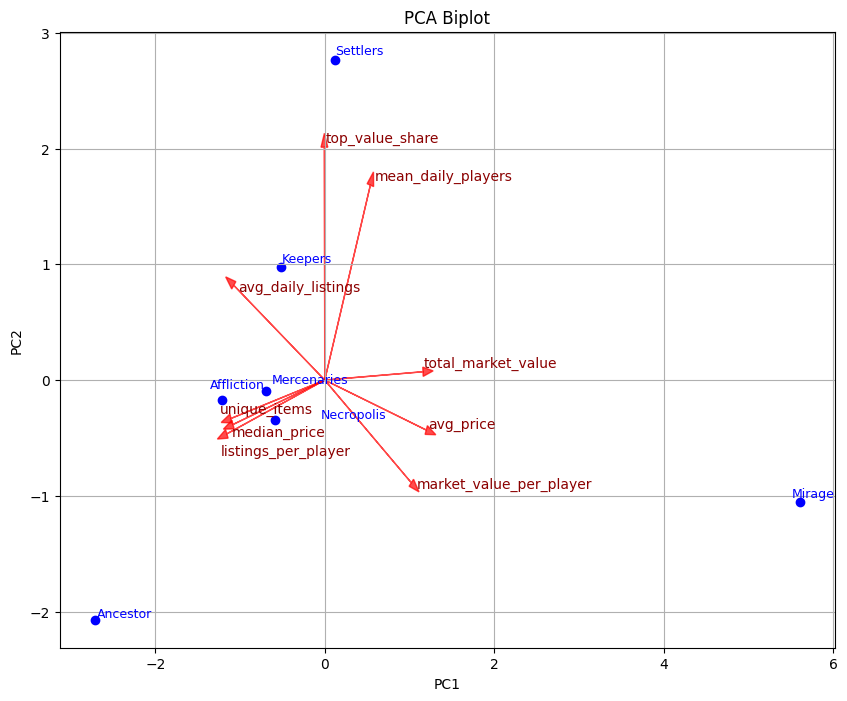

In [81]:
plt.figure(figsize=(10,8))

texts = []

plt.scatter(pca_df["PC1"], pca_df["PC2"], color="blue")

# for leagues names
for i, league in enumerate(pca_df["League"]):
    texts.append(plt.text(pca_df["PC1"][i],pca_df["PC2"][i],league,fontsize=9,color="blue"))

#for arrows
scale = 3

for i, feature in enumerate(pca_indicators.columns):
    x = pca.components_[0, i] * scale
    y = pca.components_[1, i] * scale

    plt.arrow(0, 0, x, y,color='red',alpha=0.7,head_width=0.08)
    texts.append(plt.text(x, y, feature, color='darkred'))

# labels adjustment
adjust_text(texts)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot")
plt.grid()
plt.show()

## Clustering

### K-Means

#### 1. Defining X variable

In [73]:
X = X_pca[:, :2]   # PC1, PC2

#### 2. Selection of the number of clusters

Best k (Calinski-Harabasz): 6
Best k (Silhouette): 2


<Axes: xlabel='k'>

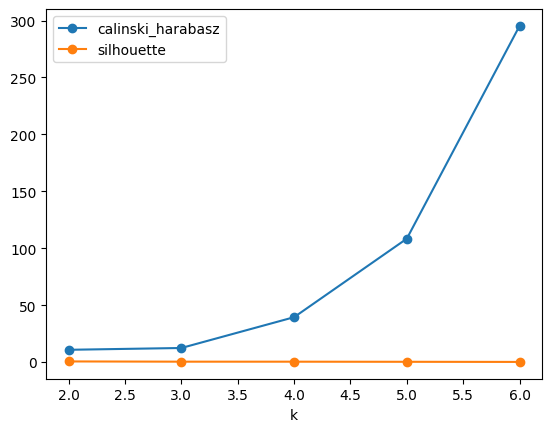

In [106]:
scores = []

for k in range(2, 7): 
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X)
    ch = calinski_harabasz_score(X, km.labels_)
    sil = silhouette_score(X, km.labels_)

    scores.append({'k': k,'calinski_harabasz': ch,'silhouette': sil})

res_df = pd.DataFrame(scores)

best_ch_k = res_df.loc[res_df['calinski_harabasz'].idxmax(), 'k']
best_sil_k = res_df.loc[res_df['silhouette'].idxmax(), 'k']

print(f"Best k (Calinski-Harabasz): {best_ch_k}")
print(f"Best k (Silhouette): {best_sil_k}")

res_df.plot(x='k', y=['calinski_harabasz','silhouette'], marker='o')

#### 3. Influence of n_init hyperparameter

<Axes: xlabel='n_init'>

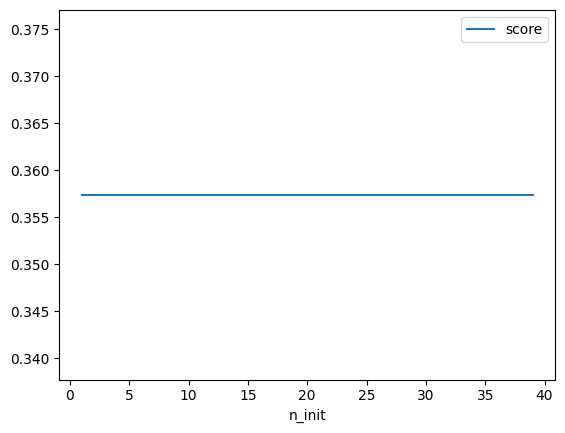

In [83]:
scores = []
for i in range(1, 40):
  kmeans = KMeans(n_clusters=4, random_state=100, n_init=i).fit(X)
  score = silhouette_score(X, kmeans.labels_)
  scores.append({'n_init': i, 'score': score})
pd.DataFrame(scores).plot(x='n_init', y='score')

#### 4. Influence of n_clusters hyperparameter

<Axes: xlabel='n_clusters'>

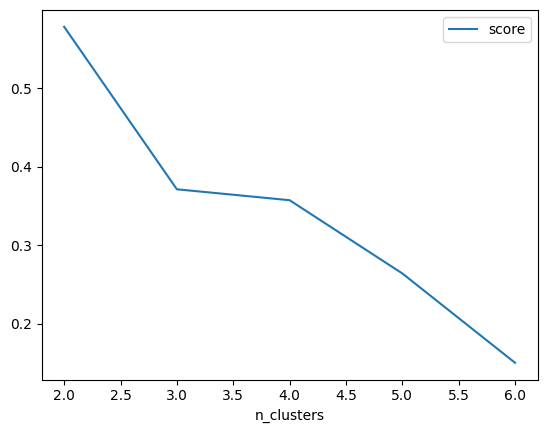

In [85]:
scores = []
for i in range(2, 7):
  kmeans = KMeans(n_clusters=i, random_state=0, n_init=10).fit(X)
  score = silhouette_score(X, kmeans.labels_)
  scores.append({'n_clusters': i, 'score': score})
pd.DataFrame(scores).plot(x='n_clusters', y='score')

#### 5. Clustering

In [88]:
X_cluster = X_pca[:, :2]

kmeans = KMeans(n_clusters=4, random_state=50)
clusters = kmeans.fit_predict(X_cluster)

pca_df["cluster"] = clusters

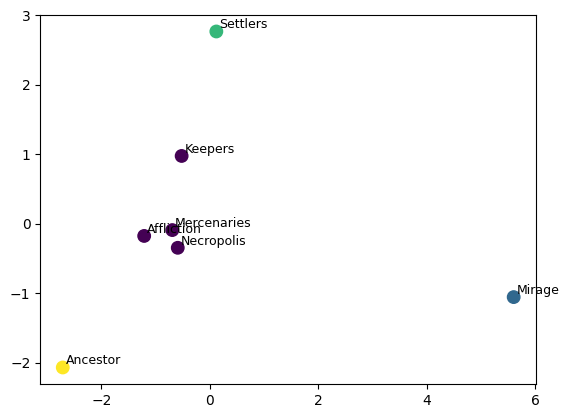

In [89]:
plt.scatter(pca_df["PC1"],pca_df["PC2"],c=pca_df["cluster"],cmap="viridis",s=80)

# for leagues names
for i, league in enumerate(pca_df["League"]):
    plt.text(pca_df["PC1"][i] + 0.05,pca_df["PC2"][i] + 0.05,league,fontsize=9)

### Hierarchical clustering

#### 1. Choosing number of clusters

Best k (Calinski-Harabasz): 6
Best k (Silhouette): 2


<Axes: xlabel='k'>

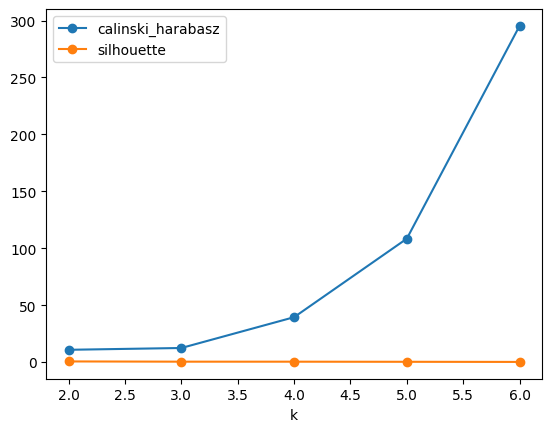

In [101]:
scores = []

for k in range(2, 7):
    hc = AgglomerativeClustering(n_clusters=k)
    labels = hc.fit_predict(X)

    ch = calinski_harabasz_score(X, labels)
    sil = silhouette_score(X, labels)

    scores.append({
        'k': k,
        'calinski_harabasz': ch,
        'silhouette': sil
    })

res_df = pd.DataFrame(scores)

best_ch_k = res_df.loc[res_df['calinski_harabasz'].idxmax(), 'k']
best_sil_k = res_df.loc[res_df['silhouette'].idxmax(), 'k']

print(f"Best k (Calinski-Harabasz): {best_ch_k}")
print(f"Best k (Silhouette): {best_sil_k}")

res_df.plot(x='k', y=['calinski_harabasz', 'silhouette'], marker='o')

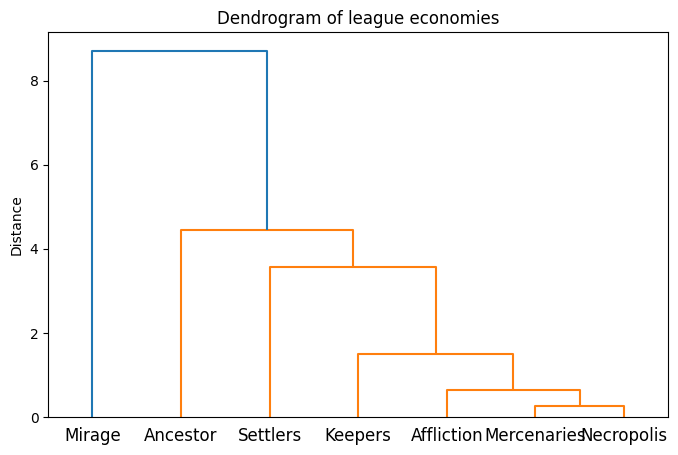

In [103]:
linked = linkage(X_cluster, method="ward")

plt.figure(figsize=(8,5))
dendrogram(linked, labels=pca_df["League"].values)
plt.title("Dendrogram of league economies")
plt.ylabel("Distance")
plt.show()

#### 2. Clustering

In [94]:
agg = AgglomerativeClustering(n_clusters=5)
clusters = agg.fit_predict(X_cluster)

pca_df["agg_cluster"] = clusters

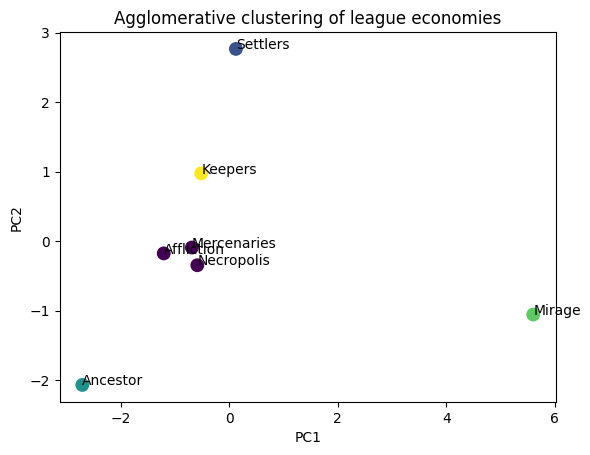

In [95]:
plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["agg_cluster"],
    cmap="viridis",
    s=80
)

for i in range(len(pca_df)):
    plt.text(
        pca_df["PC1"][i],
        pca_df["PC2"][i],
        pca_df["League"][i]
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Agglomerative clustering of league economies")
plt.show()